# 04 – Train on the full `train_filtered` table
### EDA → skewness → Gradient Descent → feature ladder → drop weak features → final equation → validation

**Scope** – every row of `train_filtered` is used (no sampling). Weeks **3–8** = training scope (week 3 only supplies the history that week 4 needs), week **9** = validation. Nothing is ever processed in one piece: weeks are streamed in **chunks of ≤ 1 million rows**.

**Flow of this notebook**
1. Load / profile the data and **EDA**
2. **Skewness** – log-transform the target, tame the extreme right tail, find skewed and *duplicate* features
3. Build the candidate features (history only – no leakage) and train a **first Gradient Descent model with all of them**
4. **Feature ladder** – the table of *intercept, coefficient, R² and MSE as each feature enters the model*
5. **Remove features that barely change the equation** → the **final feature set**
6. Train the **final equation with Gradient Descent** on the few remaining features
7. **Validate on week 9** and compare with the training R² (they should be close) → freeze the equation
8. Result tables, charts, save the model → notebook 05 applies the frozen equation to the test table

In [1]:
import sys; sys.path.insert(0, "..")
import copy, json, os, pickle, time
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import display, Markdown

from bimbo_gd import config
from bimbo_gd.db import get_engine, ping
from bimbo_gd.product_scope import (detect_products, count_rows, fetch_week_products, EDAAccumulator,
                                    NormalEquations, GramAccumulator, reset_cache_if_table_changed, formula_text, product_report)
from bimbo_gd.features import FEATURES, FEATURE_INFO, HistoricalFeatureBuilder, log_target
from bimbo_gd.gradient_descent import LinearRegressionGD
from bimbo_gd.metrics import regression_report, inventory_report

pd.set_option("display.width", 220); pd.set_option("display.max_columns", 40)
pd.options.display.float_format = "{:,.4f}".format
config.FINAL_DIR.mkdir(parents=True, exist_ok=True)

TABLE, T = config.FILTERED_TRAIN_TABLE, config.TARGET
SEED_WEEK, TRAIN_WEEKS, VAL_WEEK = config.SEED_WEEK, config.TRAIN_WEEKS_FINAL, config.VAL_WEEK_FINAL
ALL_WEEKS = [SEED_WEEK] + TRAIN_WEEKS + [VAL_WEEK]
engine = get_engine(); print("SQL connection:", "OK" if ping(engine) == 1 else "FAILED", "| table:", TABLE)
print(f"History week {SEED_WEEK} | training weeks {TRAIN_WEEKS} | validation week {VAL_WEEK}")

SQL connection: OK | table: dbo.train_filtered
History week 3 | training weeks [4, 5, 6, 7, 8] | validation week 9


### Settings (edit here, then Run All)
| Parameter | Meaning |
|---|---|
| `LEARNING_RATE`, `EPOCHS_PER_CHUNK`, `MINI_BATCH_SIZE`, `L2` | Gradient Descent settings (step size, passes per chunk, rows per update, ridge penalty) |
| `TARGET_CAP_Q` | the demand values above this quantile are capped **in the training rows only** (extreme right tail); `None` = no cap |
| `CORR_DROP` | two features with |Pearson r| at or above this are "multicollinear duplicates" (0.85 = threshold taught in MSBA 265 Module 1): only the one more related to demand is kept |
| `MIN_GAIN` | a feature is kept only if adding it raises the training R² by at least this much |
| `MIN_DROP` | a kept feature is removed if taking it out lowers the training R² by less than this |
| `MAX_FEATURES` | optional hard limit on the number of features (`None` = no limit) |

In [2]:
LEARNING_RATE    = 0.05
EPOCHS_PER_CHUNK = 10
MINI_BATCH_SIZE  = 4096
L2               = 0.0
SUB_BATCH_ROWS   = config.SUB_BATCH_ROWS      # 1,000,000
TARGET_CAP_Q     = 0.999
CORR_DROP        = 0.85
MIN_GAIN         = 0.002
MIN_DROP         = 0.001
MAX_FEATURES     = None
display(pd.DataFrame({"value": {"algorithm": "Mini-batch Gradient Descent (own NumPy code)", "learning rate (α)": LEARNING_RATE,
        "epochs per chunk": EPOCHS_PER_CHUNK, "mini-batch size": MINI_BATCH_SIZE, "L2 (λ)": L2, "max rows per chunk": SUB_BATCH_ROWS,
        "target cap (training rows only)": TARGET_CAP_Q, "duplicate-feature threshold |r|": CORR_DROP,
        "min R² gain to keep a feature": MIN_GAIN, "sampling": "none - all rows are used"}}))

,value
algorithm,Mini-batch Gradient Descent (own NumPy code)
learning rate (α),0.0500
epochs per chunk,10
mini-batch size,4096
L2 (λ),0.0000
max rows per chunk,1000000
target cap (training rows only),0.9990
duplicate-feature threshold |r|,0.8500
min R² gain to keep a feature,0.0020
sampling,none - all rows are used


## 1. Load and profile the data
First one SQL query counts the rows per week and product (nothing is downloaded yet).

In [3]:
PRODUCTS = detect_products(engine, TABLE)
counts = count_rows(engine, TABLE)
if reset_cache_if_table_changed(config.FINAL_CACHE_DIR, "train", TABLE, counts): print("The SQL table is new or has changed: old cached weeks were removed and will be re-read from SQL.")
pivot = counts.pivot_table(index="Product_ID", columns="Week", values="n_rows", aggfunc="sum", fill_value=0)
pivot["TOTAL"] = pivot.sum(axis=1)
display(pivot.loc[pivot.TOTAL.sort_values(ascending=False).index].style.format("{:,.0f}"))
week_rows = counts.groupby("Week").n_rows.sum()
missing = [w for w in ALL_WEEKS if w not in week_rows.index]
assert not missing, f"weeks {missing} are not in {TABLE}"
print(f"{len(PRODUCTS)} products: {PRODUCTS}")
print(f"Total rows: {int(week_rows.sum()):,} | largest week: {int(week_rows.max()):,} rows "
      f"-> processed in {int(np.ceil(week_rows.max() / SUB_BATCH_ROWS))} chunk(s) of <= {SUB_BATCH_ROWS:,} rows")

The SQL table is new or has changed: old cached weeks were removed and will be re-read from SQL.


Week,3,4,5,6,7,8,9,TOTAL
Product_ID,,,,,,,,
1240,"327,755","316,611","307,740","303,221","305,536","296,479","289,313","2,146,655"
1242,"310,159","302,721","296,133","292,041","291,872","280,969","269,969","2,043,864"
2233,"286,806","276,714","268,352","268,028","288,046","291,835","295,769","1,975,550"
1250,"278,623","271,788","268,122","265,906","268,414","260,197","247,438","1,860,488"
1284,"224,283","242,045","255,290","262,170","259,859","227,247","199,296","1,670,190"
1278,"198,808","198,007","198,681","202,130","206,494","201,998","191,972","1,398,090"
43285,"179,959","171,773","167,393","165,467","172,585","175,197","177,076","1,209,450"
2425,"131,353","138,797","141,981","140,011","139,225","131,091","122,060","944,518"
36610,"36,318","38,361","38,936","39,006","40,336","40,946","42,054","275,957"


10 products: [1240, 1242, 1250, 1278, 1284, 2233, 2425, 36610, 43285, 45143]
Total rows: 13,721,629 | largest week: 2,001,387 rows -> processed in 3 chunk(s) of <= 1,000,000 rows


Each week is now read from SQL (in 250k-row pieces), saved as a parquet cache file (so the next run is instant) and **profiled on the fly** by the EDA accumulator. Only one week is in memory at a time.

In [4]:
def load_week(w):
    return fetch_week_products(engine, TABLE, config.TRAIN_COLUMNS, w, None, 1, cache_dir=config.FINAL_CACHE_DIR, tag="train")

acc = EDAAccumulator()
for w in ALL_WEEKS:
    t0 = time.time(); d = load_week(w); acc.add(d)
    print(f"week {w}: {len(d):,} rows read and profiled ({time.time()-t0:.0f}s)"); del d
print(f"\nAll {acc.n:,} rows profiled.")

week 3: 2,000,167 rows read and profiled (18s)
week 4: 1,985,087 rows read and profiled (18s)
week 5: 1,968,902 rows read and profiled (15s)
week 6: 1,964,667 rows read and profiled (16s)
week 7: 2,001,387 rows read and profiled (16s)
week 8: 1,936,354 rows read and profiled (16s)
week 9: 1,865,065 rows read and profiled (17s)

All 13,721,629 rows profiled.


## 2. EDA – exploratory data analysis
### 2.1 Data quality (NULL, invalid values) – computed on ALL rows

In [5]:
display(acc.quality())
q = acc.target_quantiles((0.5, 0.9, 0.99, 0.999))
print(f"Demand = 0 in {acc.quality().loc[T, 'zeros'] / acc.n * 100:.2f}% of rows | median {q[0.5]:.0f} | P90 {q[0.9]:.0f} | P99 {q[0.99]:.0f} | P99.9 {q[0.999]:.0f}")
display(acc.describe())

,NULLs,negative values,zeros
Week,0,0,0
Agency_ID,0,0,0
Channel_ID,0,0,0
Route_SAK,0,0,0
Customer_ID,0,0,0
Product_ID,0,0,0
Sales_Units_Today,0,0,17725
Sales_Today,0,0,17725
Returns_Units_Next,0,0,13412778
Returns_Next,0,0,13412778


Demand = 0 in 0.89% of rows | median 5 | P90 25 | P99 80 | P99.9 175


,mean,std,min,max
Sales_Units_Today,10.7459,18.8785,0.0000,"3,850.0000"
Sales_Today,62.2920,158.1532,0.0000,"57,826.0000"
Returns_Units_Next,0.1210,2.7658,0.0000,"1,853.0000"
Returns_Next,0.7408,21.8101,0.0000,"33,618.8398"
Adjusted_Demand_Units,10.6640,18.7324,0.0000,"3,850.0000"


### 2.2 Per-product profile
`skew` > 1 means a long right tail: many small orders and a few very large ones.

,rows,mean,median,std,p99,max,zero_share,skew
Product_ID,,,,,,,,
1240,"2,146,655",5.67,4.0,12.30,30,"1,815",0.9%,36.32
1242,"2,043,864",5.08,4.0,6.82,25,"2,183",0.8%,68.47
2233,"1,975,550",5.62,3.0,16.84,46,"2,900",1.5%,44.34
1250,"1,860,488",6.46,4.0,18.01,40,"3,569",1.3%,40.13
1284,"1,670,190",11.70,10.0,13.06,50,"3,850",0.3%,35.20
1278,"1,398,090",13.97,10.0,16.79,72,"1,655",0.6%,13.13
43285,"1,209,450",12.53,10.0,13.80,60,"2,209",0.6%,14.18
2425,"944,518",25.12,19.0,24.66,115,"1,368",0.4%,5.01
36610,"275,957",45.95,40.0,40.36,120,"3,373",1.8%,33.79


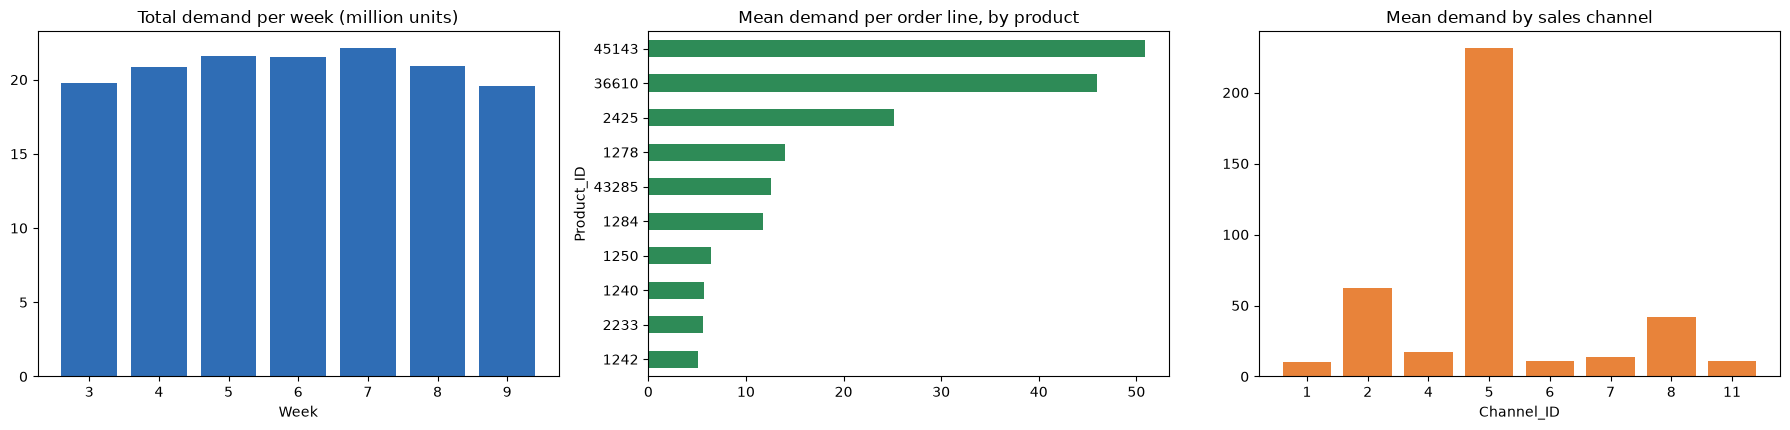

In [6]:
prof = acc.product_profile()
display(prof.style.format({"rows": "{:,.0f}", "mean": "{:.2f}", "median": "{:.1f}", "std": "{:.2f}", "p99": "{:.0f}", "max": "{:,.0f}",
                           "zero_share": "{:.1%}", "skew": "{:.2f}"}))
fig, ax = plt.subplots(1, 3, figsize=(18, 4.4))
wk = acc.weekly()
ax[0].bar(wk.index.astype(str), wk["sum"] / 1e6, color="#2f6db5"); ax[0].set_title("Total demand per week (million units)"); ax[0].set_xlabel("Week")
prof["mean"].sort_values().plot.barh(ax=ax[1], color="#2e8b57"); ax[1].set_title("Mean demand per order line, by product"); ax[1].set_ylabel("Product_ID")
ch = acc.channel(); ch = ch[ch["rows"] > 100]
ax[2].bar(ch.index.astype(str), ch["mean"], color="#e8833a"); ax[2].set_title("Mean demand by sales channel"); ax[2].set_xlabel("Channel_ID")
plt.tight_layout(); plt.show()

### 2.3 Distribution of the target and relationships
Demand is `Adjusted_Demand_Units` = units sold − units returned. The correlation matrix also shows **why same-week sales cannot be a feature**: `Sales_Units_Today` is almost the same number as the target, but it is **not available for weeks 10–11** (the test table has no sales columns). Using it would be data leakage.

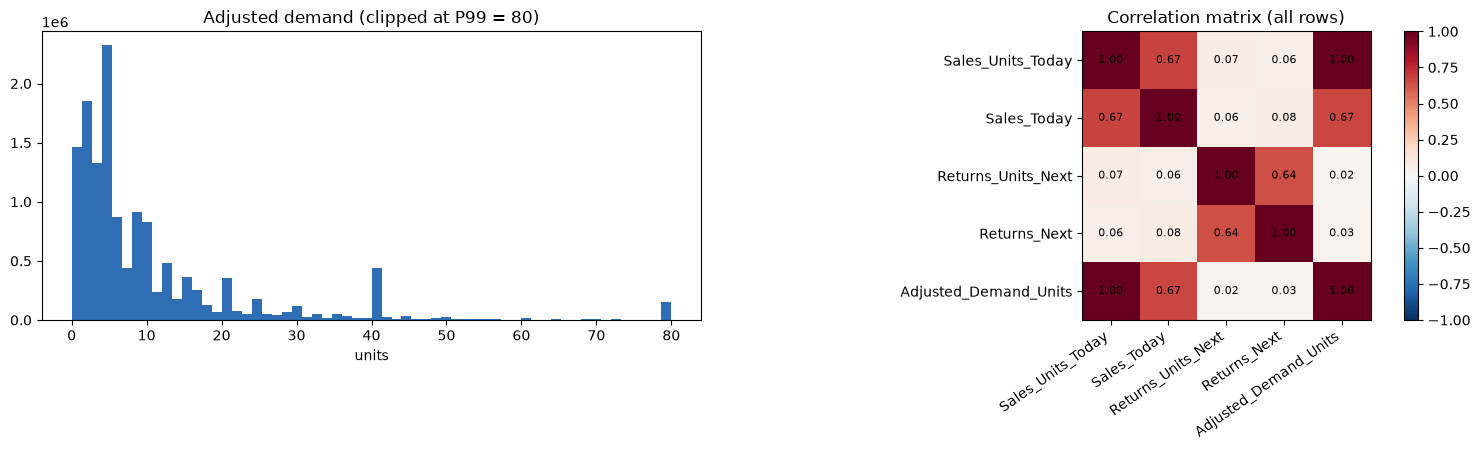

Correlation of demand with same-week sales units: 0.997  -> NOT usable for the future (leakage)


In [7]:
num = acc.NUM; corr = acc.corr()
h = acc.target_hist(); vals, cnt = h.index.to_numpy(float), h.to_numpy(float); cap = acc.target_quantiles((0.99,))[0.99]
fig, ax = plt.subplots(1, 2, figsize=(15, 4.6))
ax[0].hist(np.minimum(vals, cap), bins=60, weights=cnt, color="#2f6db5"); ax[0].set_title(f"Adjusted demand (clipped at P99 = {cap:.0f})"); ax[0].set_xlabel("units")
im = ax[1].imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1); ax[1].set_xticks(range(len(num))); ax[1].set_yticks(range(len(num)))
ax[1].set_xticklabels(num, rotation=35, ha="right"); ax[1].set_yticklabels(num)
for i in range(len(num)):
    for j in range(len(num)): ax[1].text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=8)
ax[1].set_title("Correlation matrix (all rows)"); plt.colorbar(im, ax=ax[1], fraction=.046); plt.tight_layout(); plt.show()
corr_sales = float(corr.loc[T, "Sales_Units_Today"])
print(f"Correlation of demand with same-week sales units: {corr_sales:.3f}  -> NOT usable for the future (leakage)")

## 3. Skewness
**Skewness** measures how asymmetric a distribution is (0 = symmetric, > 1 = strong right tail). A long tail lets a few giant orders dominate a squared-error fit. We **measure → transform → re-measure** (exact values over all rows).

,skewness,excess kurtosis
raw,24.1373,"2,146.6323"
square root,2.2379,13.7500
cube root,1.1629,3.3629
log1p,0.5438,0.0243


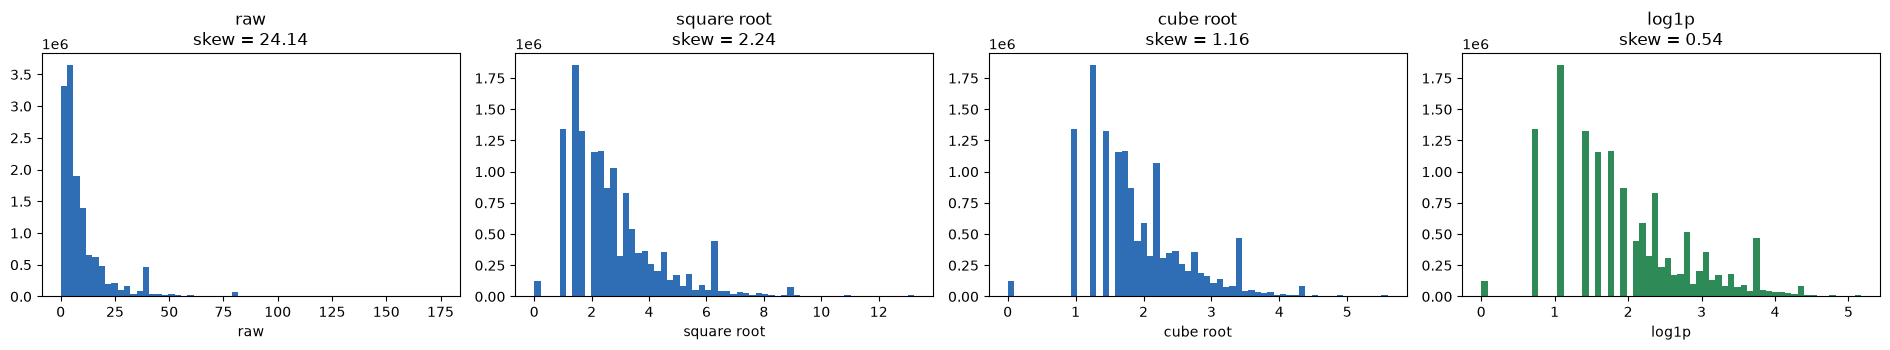

,skew (raw),skew (log1p)
Sales_Units_Today,24.0864,0.6071
Sales_Today,68.9346,0.3673
Returns_Units_Next,191.4811,10.2361
Returns_Next,703.8827,7.3375
Adjusted_Demand_Units,24.1373,0.5438


DECISION: model log1p(Adjusted_Demand_Units).
  skewness drops from 24.14 (raw) to 0.54 (log1p).
  log1p also matches the competition metric RMSLE; predictions are converted back with exp(.) - 1.


In [8]:
sk = acc.skew_target(); display(sk)
cap999 = acc.target_quantiles((0.999,))[0.999]; v = np.minimum(np.clip(vals, 0, None), cap999)
tr = {"raw": v, "square root": np.sqrt(v), "cube root": np.cbrt(v), "log1p": np.log1p(v)}
fig, ax = plt.subplots(1, 4, figsize=(19, 3.6))
for a, (k, x) in zip(ax, tr.items()):
    a.hist(x, bins=60, weights=cnt, color="#2e8b57" if k == "log1p" else "#2f6db5")
    a.set_title(f"{k}\nskew = {sk.loc[k, 'skewness']:.2f}"); a.set_xlabel(k)
plt.tight_layout(); plt.show()
sk2 = acc.skew_columns(); display(sk2)
print("DECISION: model log1p(Adjusted_Demand_Units).")
print(f"  skewness drops from {sk.loc['raw', 'skewness']:.2f} (raw) to {sk.loc['log1p', 'skewness']:.2f} (log1p).")
print("  log1p also matches the competition metric RMSLE; predictions are converted back with exp(.) - 1.")

### 3.1 The extreme right tail
Even after `log1p`, a few giant orders can pull a squared-error fit. Demand above the `TARGET_CAP_Q` quantile is therefore **capped in the training rows only**; validation and test are never touched, so the scores stay honest.

In [9]:
cap_units = acc.target_quantiles((TARGET_CAP_Q,))[TARGET_CAP_Q] if TARGET_CAP_Q else np.inf
share = float((vals[vals > cap_units] * cnt[vals > cap_units]).sum() / (vals * cnt).sum()) if TARGET_CAP_Q else 0.0
print(f"Training demand is capped at {cap_units:,.0f} units (quantile {TARGET_CAP_Q}); the capped part is {share:.2%} of all units.")
def y_train(s):                    # target used for LEARNING: log1p of capped demand
    return np.log1p(np.minimum(s.clip(lower=0).to_numpy(dtype="float64"), cap_units))

Training demand is capped at 175 units (quantile 0.999); the capped part is 3.01% of all units.


## 4. Candidate features and the first Gradient Descent model (all candidates)
Every feature is built **only from weeks before the row's week** (no leakage) – smoothed average demand of the product / customer / depot / route / channel / customer-product pair, how often they order, the pair's last two orders, their mean, weeks since last order, the pair's return rate, the product's price and return rate, and "never seen" flags.

**Expanding window** (each chunk is scored *before* it is learned, so the R² curve is honest):
```
history = week 3
for w in 4..8:   features from history -> score BEFORE learning -> Gradient Descent -> add week w to history
week 9:          features from weeks 3..8 -> validation (never learned)
```
While streaming, we also accumulate a small summary matrix (X'X, X'y, y'y). It lets us fit the *exact* least-squares solution of **any subset of features** in the next sections without reading the data again.

In [10]:
CAND = list(FEATURES)
gram_tr, gram_v1, gram_v2 = GramAccumulator(CAND), GramAccumulator(CAND), GramAccumulator(CAND)
h2_path = config.FINAL_DIR / "_builder_h2.pkl"
rng = np.random.default_rng(42)
builder = HistoricalFeatureBuilder().update(load_week(SEED_WEEK))
full = None; log_full = []
for w in TRAIN_WEEKS:
    t0 = time.time(); wk = load_week(w); order = rng.permutation(len(wk)); first = True
    for s in range(0, len(wk), SUB_BATCH_ROWS):
        sub = wk.iloc[order[s:s + SUB_BATCH_ROWS]]
        X = builder.transform(sub).to_numpy(); y = y_train(sub[T])
        if full is None:
            full = LinearRegressionGD(method="mini_batch", learning_rate=LEARNING_RATE, batch_size=MINI_BATCH_SIZE, l2=L2, verbose=False).init_scaler(X, y)
        if first: r2_before = regression_report(y, full.predict(X))["R2_log"]; first = False
        full.partial_fit(X, y, n_epochs=EPOCHS_PER_CHUNK); gram_tr.add(X, y)
    builder.update(wk)
    if w == VAL_WEEK - 2:
        with open(h2_path, "wb") as f: pickle.dump(builder, f, protocol=pickle.HIGHEST_PROTOCOL)
    log_full.append(dict(week=w, rows=len(wk), R2_before_learning=r2_before)); print(f"week {w}: {len(wk):,} rows | R² before learning (all candidates) = {r2_before:.4f} | {time.time()-t0:.0f}s"); del wk

# validation Gram of week 9 (1 week ahead: history to week 8; 2 weeks ahead: history to week 7) - never used for learning or selection
wk9 = load_week(VAL_WEEK)
with open(h2_path, "rb") as f: b_h2 = pickle.load(f)
pf = []
for s in range(0, len(wk9), SUB_BATCH_ROWS):
    sub = wk9.iloc[s:s + SUB_BATCH_ROWS]; y = log_target(sub[T])
    X1 = builder.transform(sub).to_numpy(); gram_v1.add(X1, y); gram_v2.add(b_h2.transform(sub).to_numpy(), y); pf.append(full.predict(X1))
del b_h2
print(f"\nTraining rows (weeks {TRAIN_WEEKS[0]}-{TRAIN_WEEKS[-1]}): {gram_tr.n:,} | validation rows (week {VAL_WEEK}): {gram_v1.n:,}")

week 4: 1,985,087 rows | R² before learning (all candidates) = 0.0000 | 16s
week 5: 1,968,902 rows | R² before learning (all candidates) = 0.6539 | 16s
week 6: 1,964,667 rows | R² before learning (all candidates) = 0.6693 | 16s
week 7: 2,001,387 rows | R² before learning (all candidates) = 0.6848 | 19s
week 8: 1,936,354 rows | R² before learning (all candidates) = 0.6916 | 17s

Training rows (weeks 4-8): 9,856,397 | validation rows (week 9): 1,865,065


### 4.1 Feature dictionary, per-feature skewness and multicollinearity
Following the MSBA 265 Module 1 workflow (Solis, 2026), every candidate feature is audited **one by one**:
1. **Dictionary** – what the feature means and how it is calculated.
2. **Univariate skewness** of each feature (exact, all training rows): |skew| > 3 = extremely skewed, |skew| > 1 = moderately skewed.
3. **Decision matrix** – a log transform is only applied to a *continuous positive volume*. Counts, flags and rates are **not** blindly transformed: counts here are already on a per-week log scale, flags are 0/1, and rates are bounded (a square root is used where needed). The automated "log it" rule is therefore overridden by domain knowledge.
4. **Multicollinearity audit** – if two features have |Pearson r| ≥ `CORR_DROP` (0.85) only the one more related to demand is kept.

,type,meaning,how it is calculated,skewness,diagnosis,transformation decision,corr with demand,status
mean3_cust_prod,lag,Average of the last three orders,"mean of last_cust_prod, prev_cust_prod and the third-latest order of the pair",0.65,Symmetric enough,none - already log demand,+0.786,kept
last_cust_prod,lag,Most recent demand of the store for this product,"log1p(demand) in the latest earlier week in which the pair was ordered; if new, te_cust_prod",0.58,Symmetric enough,none - already log demand,+0.752,removed: duplicate of mean3_cust_prod (r = +0.943)
prev_cust_prod,lag,The order before the most recent one,"log1p(demand) of the second-latest earlier order of the pair; if missing, last_cust_prod",0.58,Symmetric enough,none - already log demand,+0.752,removed: duplicate of mean3_cust_prod (r = +0.961)
te_cust_prod,average,Typical demand of this store for this product,"same formula, over the earlier rows of the store-product pair; if the pair is new, the product's te_product is used",2.03,Moderately skewed,none - already an average of log demand,+0.700,kept
te_product,average,Typical demand level of the product,(sum of log1p(demand) of the product's earlier rows + m*G) / (number of those rows + m),1.37,Moderately skewed,none - already an average of log demand,+0.616,kept
logcnt_product,count,How often the product is ordered,log(1 + earlier order lines of the product / weeks of history),-3.02,Extremely skewed,none - already on a per-week log scale,-0.555,removed: duplicate of te_product (r = -0.917)
log_hist_price,volume,Price level of the product,log(1 + historical sales value in pesos / units sold) of the product,-0.06,Symmetric enough,log1p applied (continuous positive volume),-0.516,kept
te_customer,average,Typical demand level of the store,"same formula, over the store's earlier rows",1.11,Moderately skewed,none - already an average of log demand,+0.474,kept
te_route,average,Typical demand level of the delivery route,"same formula, over the route's earlier rows",1.80,Moderately skewed,none - already an average of log demand,+0.410,kept
ret_cust_prod,rate,Share of this store's product that came back unsold,"sqrt of (returned units + 5*p) / (sold units + 5), where p = the product's overall return rate; the square root reduces the right skew",6.31,Extremely skewed,square root used where needed (bounded 0-1),-0.258,kept


22 candidates -> 18 after removing constant / multicollinear features (|r| >= 0.85).   Target skewness after log1p and cap: 0.52


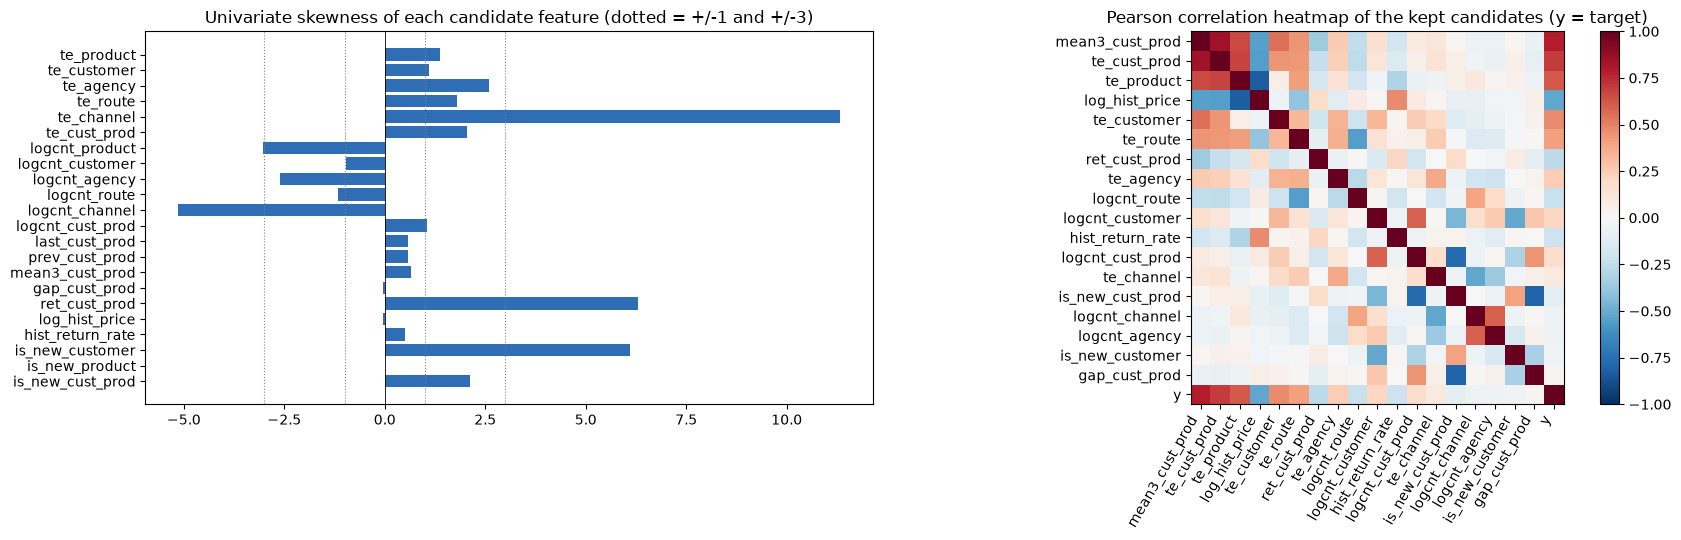

In [11]:
mom, corr = gram_tr.moments(), gram_tr.corr()
sk_before = mom.loc["y", "skewness"]
const = [f for f in CAND if mom.loc[f, "std"] < 1e-6]
rank = [f for f in corr["y"].drop("y").abs().sort_values(ascending=False).index if f not in const]
keep, reason = [], {f: "constant (no information)" for f in const}
for f in rank:
    twin = next((g for g in keep if abs(corr.loc[f, g]) >= CORR_DROP), None)
    if twin is None: keep.append(f)
    else: reason[f] = f"duplicate of {twin} (r = {corr.loc[f, twin]:+.3f})"

def diagnosis(s):
    if not np.isfinite(s): return "n/a"
    return "Extremely skewed" if abs(s) > 3 else "Moderately skewed" if abs(s) > 1 else "Symmetric enough"
ACTION = {"average": "none - already an average of log demand", "count": "none - already on a per-week log scale",
          "lag": "none - already log demand", "rate": "square root used where needed (bounded 0-1)",
          "volume": "log1p applied (continuous positive volume)", "flag": "none - 0/1 indicator"}
cand_tbl = pd.DataFrame({
    "type": [FEATURE_INFO[f][0] for f in CAND], "meaning": [FEATURE_INFO[f][1] for f in CAND],
    "how it is calculated": [FEATURE_INFO[f][2] for f in CAND],
    "skewness": mom.loc[CAND, "skewness"].to_numpy(), "diagnosis": [diagnosis(s) for s in mom.loc[CAND, "skewness"]],
    "transformation decision": [ACTION[FEATURE_INFO[f][0]] for f in CAND],
    "corr with demand": corr.loc[CAND, "y"].to_numpy(),
    "status": ["kept" if f in keep else "removed: " + reason[f] for f in CAND]}, index=CAND)
with pd.option_context("display.max_colwidth", 90, "display.max_rows", None):
    display(cand_tbl.sort_values("corr with demand", key=abs, ascending=False).style.format({"skewness": "{:.2f}", "corr with demand": "{:+.3f}"}))
cand_tbl.to_csv(config.FINAL_DIR / "feature_dictionary.csv")
print(f"{len(CAND)} candidates -> {len(keep)} after removing constant / multicollinear features (|r| >= {CORR_DROP}).   Target skewness after log1p and cap: {sk_before:.2f}")
fig, ax = plt.subplots(1, 2, figsize=(17, 5.5))
ax[0].barh(CAND[::-1], mom.loc[CAND[::-1], "skewness"], color="#2f6db5"); ax[0].axvline(0, color="k", lw=.6)
for t in (-3, -1, 1, 3): ax[0].axvline(t, color="gray", ls=":", lw=.8)
ax[0].set_title("Univariate skewness of each candidate feature (dotted = +/-1 and +/-3)")
cm = corr.loc[keep + ["y"], keep + ["y"]]; im = ax[1].imshow(cm, cmap="RdBu_r", vmin=-1, vmax=1)
ax[1].set_xticks(range(len(cm))); ax[1].set_yticks(range(len(cm))); ax[1].set_xticklabels(cm.columns, rotation=60, ha="right"); ax[1].set_yticklabels(cm.index)
ax[1].set_title("Pearson correlation heatmap of the kept candidates (y = target)"); plt.colorbar(im, ax=ax[1], fraction=.046); plt.tight_layout(); plt.show()

## 5. Feature ladder – what each feature adds
Starting from the intercept alone, the feature that raises the **training R²** the most is added first, then the next, and so on. For every step the table shows the equation's **intercept**, the **coefficient of the feature that just entered**, the **R² and MSE on the training rows** (weeks 4–8) and – for information only – on the **validation week**. *Selection uses training numbers only; validation is never used to choose features.*

(The ladder is computed with the exact least-squares solution – the optimum that Gradient Descent converges to – so that all steps can be fitted instantly. Gradient Descent trains the first (all-features) model above and the final equation in section 6.)

,step,feature_added,intercept,coef_of_new_feature,R2_train,MSE_train,R2_valid,MSE_valid,gain_R2
0,0,(intercept only),+1.9874,+nan,0.0000,0.8359,-0.0013,0.8408,+0.0000
1,1,mean3_cust_prod,+0.2069,+0.8794,0.6182,0.3192,0.6661,0.2804,+0.6182
2,2,te_product,-0.1021,+0.2850,0.6341,0.3058,0.6693,0.2777,+0.0160
3,3,te_customer,-0.9669,+0.4567,0.6497,0.2928,0.6812,0.2677,+0.0156
4,4,is_new_cust_prod,-0.8517,-0.2721,0.6598,0.2843,0.6851,0.2645,+0.0101
5,5,logcnt_customer,-0.9472,+0.0952,0.6616,0.2828,0.6856,0.2640,+0.0018
6,6,logcnt_channel,-0.2907,-0.0489,0.6637,0.2811,0.6875,0.2624,+0.0021
7,7,hist_return_rate,-0.1823,-7.7929,0.6645,0.2805,0.6866,0.2632,+0.0008
8,8,te_cust_prod,-0.3454,+0.1566,0.6654,0.2797,0.6883,0.2618,+0.0009
9,9,ret_cust_prod,-0.3621,+0.3502,0.6660,0.2792,0.6887,0.2614,+0.0006


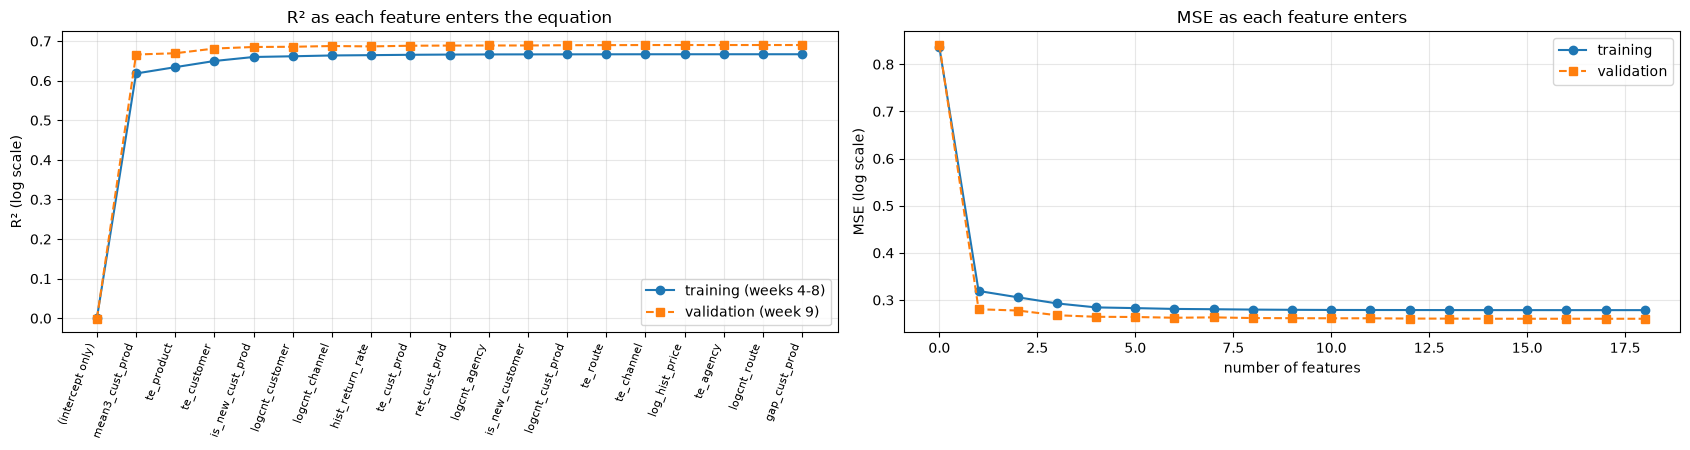

In [12]:
def run_ladder(pool):
    chosen, rows = [], []
    b0, b = gram_tr.fit([]); r_tr = gram_tr.score([], b0, b); r_v = gram_v1.score([], b0, b)
    rows.append(dict(step=0, feature_added="(intercept only)", intercept=b0, coef_of_new_feature=np.nan,
                     R2_train=r_tr["R2"], MSE_train=r_tr["MSE"], R2_valid=r_v["R2"], MSE_valid=r_v["MSE"], gain_R2=0.0))
    prev = r_tr["R2"]; left = list(pool)
    while left:
        best = None
        for f in left:
            b0, b = gram_tr.fit(chosen + [f]); r = gram_tr.score(chosen + [f], b0, b)["R2"]
            if best is None or r > best[0]: best = (r, f)
        f = best[1]; chosen.append(f); left.remove(f)
        b0, b = gram_tr.fit(chosen); r_tr = gram_tr.score(chosen, b0, b); r_v = gram_v1.score(chosen, b0, b)
        rows.append(dict(step=len(chosen), feature_added=f, intercept=b0, coef_of_new_feature=b[chosen.index(f)],
                         R2_train=r_tr["R2"], MSE_train=r_tr["MSE"], R2_valid=r_v["R2"], MSE_valid=r_v["MSE"], gain_R2=r_tr["R2"] - prev))
        prev = r_tr["R2"]
    return pd.DataFrame(rows), chosen

ladder, order_in = run_ladder(keep)
display(ladder.style.format({"intercept": "{:+.4f}", "coef_of_new_feature": "{:+.4f}", "R2_train": "{:.4f}", "MSE_train": "{:.4f}",
                             "R2_valid": "{:.4f}", "MSE_valid": "{:.4f}", "gain_R2": "{:+.4f}"}).bar(subset=["R2_train"], color="#9ecae1", vmin=0, vmax=1))
fig, ax = plt.subplots(1, 2, figsize=(17, 4.6))
ax[0].plot(ladder.step, ladder.R2_train, "o-", label="training (weeks 4-8)"); ax[0].plot(ladder.step, ladder.R2_valid, "s--", label=f"validation (week {VAL_WEEK})")
ax[0].set_xticks(ladder.step); ax[0].set_xticklabels(ladder.feature_added, rotation=70, ha="right", fontsize=8); ax[0].set_ylabel("R² (log scale)")
ax[0].set_title("R² as each feature enters the equation"); ax[0].grid(alpha=.3); ax[0].legend()
ax[1].plot(ladder.step, ladder.MSE_train, "o-", label="training"); ax[1].plot(ladder.step, ladder.MSE_valid, "s--", label="validation")
ax[1].set_xlabel("number of features"); ax[1].set_ylabel("MSE (log scale)"); ax[1].set_title("MSE as each feature enters"); ax[1].grid(alpha=.3); ax[1].legend()
plt.tight_layout(); plt.show()

## 5.1 Drop the features that barely change the equation
1. **Forward rule** – walk down the ladder and stop at the first feature whose R² gain is below `MIN_GAIN`.
2. **Backward check** – for every kept feature, refit *without* it. If the training R² falls by less than `MIN_DROP`, the feature is not needed and is removed.
The survivors are the **final features**.

In [13]:
sel = []
for f, g in zip(ladder.feature_added[1:], ladder.gain_R2[1:]):
    if g < MIN_GAIN or (MAX_FEATURES and len(sel) >= MAX_FEATURES): break
    sel.append(f)
if not sel: sel = list(order_in[:1])
def r2_of(fs): b0, b = gram_tr.fit(fs); return gram_tr.score(fs, b0, b)["R2"]
while len(sel) > 1:
    base_r2 = r2_of(sel); loss = {f: base_r2 - r2_of([g for g in sel if g != f]) for f in sel}
    f_min = min(loss, key=loss.get)
    if loss[f_min] < MIN_DROP: sel.remove(f_min)
    else: break
SEL = list(sel); b0, b = gram_tr.fit(SEL); base_r2 = gram_tr.score(SEL, b0, b)["R2"]
drop_tbl = pd.DataFrame({"R2_without_this_feature": {f: r2_of([g for g in SEL if g != f]) for f in SEL}})
drop_tbl["R2_lost_if_removed"] = base_r2 - drop_tbl["R2_without_this_feature"]
drop_tbl["coefficient"] = dict(zip(SEL, b)); drop_tbl = drop_tbl.sort_values("R2_lost_if_removed", ascending=False)
display(drop_tbl.style.format({"R2_without_this_feature": "{:.4f}", "R2_lost_if_removed": "{:.4f}", "coefficient": "{:+.4f}"}))
removed = [f for f in CAND if f not in SEL]
print(f"FINAL FEATURES ({len(SEL)} of {len(CAND)} candidates): {SEL}")
print(f"Removed (little or no effect on the equation): {removed}")
print(f"Training R² with the final features (exact least squares): {base_r2:.4f}   vs all {len(keep)} features: {ladder.R2_train.iloc[-1]:.4f}")

,R2_without_this_feature,R2_lost_if_removed,coefficient
mean3_cust_prod,0.5757,0.0841,+0.5947
te_product,0.6309,0.0289,+0.4385
te_customer,0.6478,0.0120,+0.4047
is_new_cust_prod,0.6497,0.0101,-0.2721


FINAL FEATURES (4 of 22 candidates): ['mean3_cust_prod', 'te_product', 'te_customer', 'is_new_cust_prod']
Removed (little or no effect on the equation): ['te_agency', 'te_route', 'te_channel', 'te_cust_prod', 'logcnt_product', 'logcnt_customer', 'logcnt_agency', 'logcnt_route', 'logcnt_channel', 'logcnt_cust_prod', 'last_cust_prod', 'prev_cust_prod', 'gap_cust_prod', 'ret_cust_prod', 'log_hist_price', 'hist_return_rate', 'is_new_customer', 'is_new_product']
Training R² with the final features (exact least squares): 0.6598   vs all 18 features: 0.6668


## 6. Final equation – Gradient Descent on the final features only
The data are streamed once more (same expanding window, same chunks), but now Gradient Descent learns only the final features.

In [14]:
model = None
builder = HistoricalFeatureBuilder().update(load_week(SEED_WEEK))
ne_sel = None; log_rows = []; rng = np.random.default_rng(42)
for w in TRAIN_WEEKS:
    t0 = time.time(); wk = load_week(w); order = rng.permutation(len(wk)); first = True; n_chunks = 0
    for s in range(0, len(wk), SUB_BATCH_ROWS):
        sub = wk.iloc[order[s:s + SUB_BATCH_ROWS]]
        X = builder.transform(sub)[SEL].to_numpy(); y = y_train(sub[T])
        if model is None:
            model = LinearRegressionGD(method="mini_batch", learning_rate=LEARNING_RATE, batch_size=MINI_BATCH_SIZE, l2=L2, verbose=False).init_scaler(X, y)
        if first: before = regression_report(y, model.predict(X)); first = False
        loss = model.partial_fit(X, y, n_epochs=EPOCHS_PER_CHUNK); n_chunks += 1; X_last, y_last = X, y
    builder.update(wk)
    log_rows.append(dict(week=w, rows=len(wk), chunks=n_chunks, R2_before_learning=before["R2_log"], RMSLE_before_learning=before["RMSLE"], train_loss_after=loss, seconds=round(time.time() - t0, 1)))
    print(f"week {w}: {len(wk):,} rows in {n_chunks} chunk(s) | R² before learning = {before['R2_log']:.4f} | loss after = {loss:.5f} | {time.time()-t0:.0f}s"); del wk
trainlog = pd.DataFrame(log_rows); display(trainlog)
w0, coef = model.raw_coefficients()
tr_gd = gram_tr.score(SEL, w0, coef); cf_int, cf_coef = gram_tr.fit(SEL)
print(f"\nTRAINING (all {gram_tr.n:,} rows of weeks {TRAIN_WEEKS[0]}-{TRAIN_WEEKS[-1]}): R² = {tr_gd['R2']:.4f} | MSE = {tr_gd['MSE']:.4f}   (exact least squares: R² = {gram_tr.score(SEL, cf_int, cf_coef)['R2']:.4f})")

week 4: 1,985,087 rows in 2 chunk(s) | R² before learning = 0.0000 | loss after = 0.15310 | 9s
week 5: 1,968,902 rows in 2 chunk(s) | R² before learning = 0.6499 | loss after = 0.14526 | 9s
week 6: 1,964,667 rows in 2 chunk(s) | R² before learning = 0.6669 | loss after = 0.13927 | 9s
week 7: 2,001,387 rows in 3 chunk(s) | R² before learning = 0.6790 | loss after = 0.14550 | 10s
week 8: 1,936,354 rows in 2 chunk(s) | R² before learning = 0.6864 | loss after = 0.13255 | 9s


,week,rows,chunks,R2_before_learning,RMSLE_before_learning,train_loss_after,seconds
0,4,1985087,2,0.0000,0.8959,0.1531,8.7000
1,5,1968902,2,0.6499,0.5397,0.1453,8.5000
2,6,1964667,2,0.6669,0.5293,0.1393,9.1000
3,7,2001387,3,0.6790,0.5236,0.1455,10.1000
4,8,1936354,2,0.6864,0.5158,0.1325,9.3000



TRAINING (all 9,856,397 rows of weeks 4-8): R² = 0.6558 | MSE = 0.2877   (exact least squares: R² = 0.6598)


### Gradient Descent progress
The loss must go down (dotted lines = week boundaries). The third chart tries other learning rates on the last training chunk.

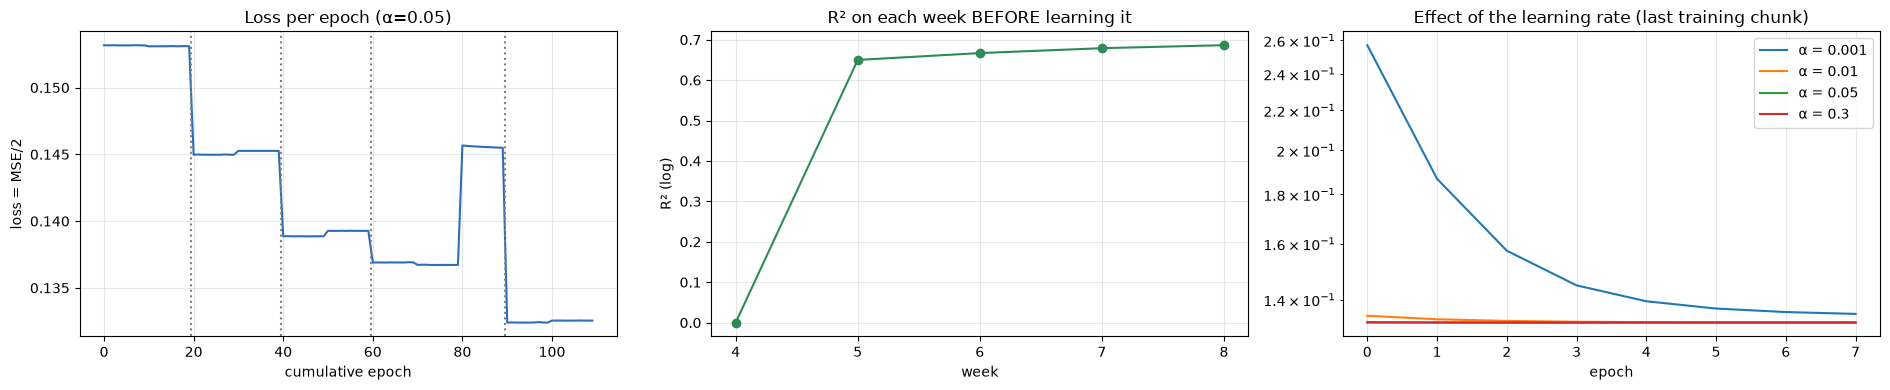

In [15]:
fig, ax = plt.subplots(1, 3, figsize=(19, 4))
ax[0].plot(model.history["train_loss"], color="#2f6db5"); ax[0].set_title(f"Loss per epoch (α={LEARNING_RATE})")
ax[0].set_xlabel("cumulative epoch"); ax[0].set_ylabel("loss = MSE/2"); ax[0].grid(alpha=.3)
cum = np.cumsum([r["chunks"] for r in log_rows]) * EPOCHS_PER_CHUNK
for c in cum[:-1]: ax[0].axvline(c - .5, color="gray", ls=":")
ax[1].plot(trainlog.week.astype(str), trainlog.R2_before_learning, "o-", color="#2e8b57"); ax[1].set_title("R² on each week BEFORE learning it")
ax[1].set_xlabel("week"); ax[1].set_ylabel("R² (log)"); ax[1].grid(alpha=.3)
for lr in [0.001, 0.01, 0.05, 0.3]:
    m = LinearRegressionGD(method="mini_batch", learning_rate=lr, batch_size=MINI_BATCH_SIZE, n_epochs=8, patience=99, verbose=False).fit(X_last, y_last)
    ax[2].plot(m.history["train_loss"], label=f"α = {lr}")
ax[2].set_yscale("log"); ax[2].set_title("Effect of the learning rate (last training chunk)"); ax[2].set_xlabel("epoch"); ax[2].legend(); ax[2].grid(alpha=.3)
plt.tight_layout(); plt.show()

## 7. Validation on week 9 (never learned, never used to select features)
Week 9 is scored three ways: **1 week ahead** (history to week 8, like test week 10), **2 weeks ahead** (history to week 7, like test week 11) and with the exact least-squares solution. The decisive comparison is **training R² vs validation R²**: if validation is not clearly worse than training, the equation generalises and can be frozen (validation may even be a bit higher, because weeks 4-5 have only a short history).

In [ ]:
with open(h2_path, "rb") as f: b_h2 = pickle.load(f)
parts, y_l, p1_l, p2_l, pcf_l, ps_l = [], [], [], [], [], []
F1 = order_in[0]                                   # the single most useful feature (step 1 of the ladder) = Baseline 2
b0_1, b_1 = gram_tr.fit([F1]); j1 = SEL.index(F1) if F1 in SEL else None
fs, fss, X_first = np.zeros(len(SEL)), np.zeros(len(SEL)), None
for s in range(0, len(wk9), SUB_BATCH_ROWS):
    sub = wk9.iloc[s:s + SUB_BATCH_ROWS]
    Xd = builder.transform(sub)[SEL]; X = Xd.to_numpy(); y = log_target(sub[T])
    p1 = model.predict(X); p2 = model.predict(b_h2.transform(sub)[SEL].to_numpy()); pcf = cf_int + X @ cf_coef
    fs += X.sum(axis=0); fss += (X ** 2).sum(axis=0)
    if X_first is None: X_first = Xd.iloc[:2000].copy()
    parts.append(pd.DataFrame({"Product_ID": sub["Product_ID"].to_numpy(), "Customer_ID": sub["Customer_ID"].to_numpy(), "Adjusted_Demand_Units": sub[T].to_numpy()}))
    ps_l.append(b0_1 + (X[:, j1] if j1 is not None else builder.transform(sub)[F1].to_numpy()) * b_1[0])
    y_l.append(y); p1_l.append(p1); p2_l.append(p2); pcf_l.append(pcf)
del b_h2; os.remove(h2_path)
y9, pred9, pred_h2, pred_cf = map(np.concatenate, (y_l, p1_l, p2_l, pcf_l))
y_train_mean = gram_tr.G[0, -1] / gram_tr.n
m1, m2, mcf = regression_report(y9, pred9), regression_report(y9, pred_h2), regression_report(y9, pred_cf)
base = regression_report(y9, np.full_like(y9, y_train_mean))
m_all = regression_report(y9, np.concatenate(pf))
res = pd.DataFrame({"Final equation, Gradient Descent (1 week ahead)": m1, "Final equation, Gradient Descent (2 weeks ahead)": m2,
                    "Final features, exact least squares": mcf, f"First model: all {len(CAND)} candidates (GD)": m_all, f"Baseline 2: best single feature ({F1})": regression_report(y9, np.concatenate(ps_l)),
                    "Baseline 1: always the training mean": base}).T
res["MSE_log"] = res["RMSLE"] ** 2
display(res[["R2_log", "MSE_log", "RMSLE", "R2_units", "MAE_units", "RMSE_units"]])
nv = len(y9); fmean = fs / nv; fstd = np.sqrt(np.maximum(fss / nv - fmean ** 2, 0))
gap = tr_gd["R2"] - m1["R2_log"]
cmp_tbl = pd.DataFrame({"R²": {"training (weeks 4-8)": tr_gd["R2"], f"validation (week {VAL_WEEK})": m1["R2_log"]},
                        "MSE": {"training (weeks 4-8)": tr_gd["MSE"], f"validation (week {VAL_WEEK})": m1["RMSLE"] ** 2}})
display(cmp_tbl.style.format("{:.4f}"))
print(f"Training R² - validation R² = {gap:+.4f} -> " + ("consistent: validation is not worse than training, the equation generalises and can be FROZEN." if gap <= 0.03 else "validation is clearly worse than training: possible over-fitting, investigate before using it."))
print(f"validation rows: {nv:,}")

,R2_log,MSE_log,RMSLE,R2_units,MAE_units,RMSE_units
"Final equation, Gradient Descent (1 week ahead)",0.6906,0.2598,0.5097,0.6416,4.1734,11.1940
"Final equation, Gradient Descent (2 weeks ahead)",0.6808,0.2681,0.5178,0.6266,4.2423,11.4249
"Final features, exact least squares",0.6851,0.2645,0.5142,0.6419,4.2547,11.1882
First model: all 22 candidates (GD),0.6980,0.2536,0.5036,0.4180,4.2010,14.2636
Baseline 2: best single feature (mean3_cust_prod),0.6661,0.2804,0.5295,0.6373,4.3128,11.2604
Baseline 1: always the training mean,-0.0013,0.8408,0.9170,-0.0502,7.8985,19.1607


,R²,MSE
training (weeks 4-8),0.6558,0.2877
validation (week 9),0.6906,0.2598


Training R² - validation R² = -0.0348 -> consistent: validation is not worse than training, the equation generalises and can be FROZEN.
Target R² > 0.80: training not reached | validation not reached
validation rows: 1,865,065


## 8. FINAL EQUATION – R², intercept and coefficients

In [17]:
chk = np.allclose(w0 + X_first.to_numpy() @ coef, pred9[:len(X_first)])      # the formula reproduces the model exactly
order = np.argsort(-np.abs(model.w))
formula = formula_text(w0, coef, SEL, order)

display(Markdown(f"""### Final result (validation week {VAL_WEEK}, never seen during learning; {nv:,} rows)
| | |
|---|---|
| **R² on TRAINING rows (weeks 4-8)** | **{tr_gd['R2']:.4f}** |
| MSE on training rows | {tr_gd['MSE']:.4f} |
| **R² on VALIDATION (log scale, main metric)** | **{m1['R2_log']:.4f}** |
| MSE on validation | {m1['RMSLE']**2:.4f} |
| R² (product units) | {m1['R2_units']:.4f} |
| RMSLE | {m1['RMSLE']:.4f} |
| MAE (units) | {m1['MAE_units']:.2f} |
| **Intercept w0** (original scale) | **{w0:+.4f}** |
| Intercept b (standardised features) | {model.b:+.4f} |
| R² if forecasting 2 weeks ahead (like test week 11) | {m2['R2_log']:.4f} |
| R² of the exact least-squares solution (reference) | {mcf['R2_log']:.4f} |
| R² of the baseline (always the mean) | {base['R2_log']:.4f} |
| Formula reproduces the model exactly | {chk} |"""))
print("FINAL FORMULA (terms sorted by importance)\n" + "=" * 62)
print(formula)

### Final result (validation week 9, never seen during learning; 1,865,065 rows)
| | |
|---|---|
| **R² on TRAINING rows (weeks 4-8)** | **0.6558** |
| MSE on training rows | 0.2877 |
| **R² on VALIDATION (log scale, main metric)** | **0.6906** |
| MSE on validation | 0.2598 |
| R² (product units) | 0.6416 |
| RMSLE | 0.5097 |
| MAE (units) | 4.17 |
| **Intercept w0** (original scale) | **-0.6570** |
| Intercept b (standardised features) | +1.9415 |
| R² if forecasting 2 weeks ahead (like test week 11) | 0.6808 |
| R² of the exact least-squares solution (reference) | 0.6851 |
| R² of the baseline (always the mean) | -0.0013 |
| Formula reproduces the model exactly | True |

FINAL FORMULA (terms sorted by importance)
log1p(Adjusted_Demand) = -0.6570
                        +0.6483 * mean3_cust_prod
                        +0.3452 * te_product
                        -0.3403 * is_new_cust_prod
                        +0.3287 * te_customer
Adjusted_Demand = exp( log1p(Adjusted_Demand) ) - 1


**How to read the intercept.** `w0` is the predicted log-demand when *every* feature equals 0. Features such as the average demand of a product are never 0, so `w0` alone is not a demand level; it anchors the formula. The *standardised* intercept `b` is easier to interpret: it is the predicted log-demand for a row with average feature values.

In [18]:
coefs_df = pd.DataFrame({"feature": SEL, "weight (original scale)": coef, "weight (standardised)": model.w, "std of feature": model.sigma})
coefs_df = coefs_df.reindex(coefs_df["weight (standardised)"].abs().sort_values(ascending=False).index).reset_index(drop=True)
coefs_df["rank"] = range(1, len(coefs_df) + 1)
display(coefs_df.style.format({"weight (original scale)": "{:+.4f}", "weight (standardised)": "{:+.4f}", "std of feature": "{:.4f}"})
        .bar(subset=["weight (standardised)"], align="zero", color=["#d65f5f", "#5fba7d"]))

,feature,weight (original scale),weight (standardised),std of feature,rank
0,mean3_cust_prod,+0.6483,+0.5296,0.8168,1
1,te_product,+0.3452,+0.1866,0.5405,2
2,is_new_cust_prod,-0.3403,-0.1189,0.3493,3
3,te_customer,+0.3287,+0.1103,0.3356,4


**Worked example** – one row of week 9, with the raw data next to the features that were looked up in the history, then calculated by hand with the formula:

In [19]:
val = pd.concat(parts, ignore_index=True)
val["y_log"], val["pred_log"] = y9, pred9
val["Predicted_Demand"] = np.clip(np.expm1(pred9), 0, None); val["Error"] = val["Predicted_Demand"] - val["Adjusted_Demand_Units"]; del parts
i = 0; row = X_first.iloc[i].to_numpy(); contrib = coef * row
display(val.loc[[i], ["Customer_ID", "Product_ID", "Adjusted_Demand_Units"]])
ex = pd.DataFrame({"feature": SEL, "x (looked up from history)": row, "weight": coef, "contribution = weight * x": contrib})
ex = ex.reindex(ex["contribution = weight * x"].abs().sort_values(ascending=False).index)
display(ex.head(8).style.format({"x (looked up from history)": "{:.4f}", "weight": "{:+.4f}", "contribution = weight * x": "{:+.4f}"}))
pl = w0 + contrib.sum()
print(f"Product {val.Product_ID[i]}, customer {val.Customer_ID[i]}: log1p(demand) = {w0:+.4f} + ({contrib.sum():+.4f}) = {pl:.4f}")
print(f"Predicted demand = exp({pl:.4f}) - 1 = {np.expm1(pl):.2f} units | actual = {val.Adjusted_Demand_Units[i]}")

,Customer_ID,Product_ID,Adjusted_Demand_Units
0,1629109,1278,28


,feature,x (looked up from history),weight,contribution = weight * x
0,mean3_cust_prod,3.6008,+0.6483,+2.3345
2,te_customer,2.8639,+0.3287,+0.9413
1,te_product,2.3891,+0.3452,+0.8246
3,is_new_cust_prod,0.0000,-0.3403,-0.0000


Product 1278, customer 1629109: log1p(demand) = -0.6570 + (+4.1004) = 3.4434
Predicted demand = exp(3.4434) - 1 = 30.29 units | actual = 28


### Result for each product (validation week 9)
`Actual_Mean` / `Predicted_Mean` = average units per order line (the expected demand of that product); totals are summed units.

In [20]:
prod_res = product_report(val)
with pd.option_context("display.max_rows", None):
    display(prod_res.style.format({"n_rows": "{:,.0f}", "Actual_Mean": "{:.2f}", "Predicted_Mean": "{:.2f}", "Actual_Total": "{:,.0f}",
                                   "Predicted_Total": "{:,.0f}", "MAE_units": "{:.2f}", "R2_log": "{:.3f}", "Error_%": "{:+.1f}%"}))
print(f"All products together: actual {prod_res.Actual_Total.sum():,.0f} units vs predicted {prod_res.Predicted_Total.sum():,.0f} units")

,Product_ID,n_rows,Actual_Mean,Predicted_Mean,Actual_Total,Predicted_Total,MAE_units,R2_log,Error_%
0,2425,"122,060",22.92,22.02,"2,797,541","2,687,432",8.87,0.476,-3.9%
1,1278,"191,972",13.84,11.69,"2,656,733","2,244,221",6.06,0.443,-15.5%
2,1284,"199,296",11.75,10.66,"2,341,652","2,124,854",4.98,0.352,-9.3%
3,43285,"177,076",12.16,10.84,"2,152,463","1,918,691",5.00,0.417,-10.9%
4,36610,"42,054",46.26,42.51,"1,945,380","1,787,804",13.27,0.141,-8.1%
5,2233,"295,769",5.55,4.11,"1,641,789","1,215,344",2.47,0.683,-26.0%
6,1240,"289,313",5.55,4.78,"1,604,987","1,384,147",2.39,0.519,-13.8%
7,1250,"247,438",6.36,5.34,"1,574,328","1,320,984",2.81,0.565,-16.1%
8,45143,"30,118",50.86,47.18,"1,531,710","1,421,109",14.04,0.185,-7.2%
9,1242,"269,969",4.86,4.43,"1,311,004","1,196,166",2.08,0.462,-8.8%


All products together: actual 19,557,587 units vs predicted 17,300,752 units


### Prediction table: customers (rows) × products (columns)
Each cell = **predicted units** of that product for that customer in validation week 9 (blank = no order that week). Several order lines of the same customer and product are added up. Below it, the **actual** units for the same customers. The full tables (all customers) are saved as CSV files you can open in Excel.

In [21]:
pv_pred = val.pivot_table(index="Customer_ID", columns="Product_ID", values="Predicted_Demand", aggfunc="sum")
pv_act = val.pivot_table(index="Customer_ID", columns="Product_ID", values="Adjusted_Demand_Units", aggfunc="sum")
cols_ = [p for p in PRODUCTS if p in pv_pred.columns]; pv_pred, pv_act = pv_pred[cols_], pv_act[cols_]
TOP_N = 25
top_c = pv_pred.sum(axis=1).sort_values(ascending=False).head(TOP_N).index
print(f"PREDICTED units - the {TOP_N} customers with the largest predicted volume (all customers: {len(pv_pred):,}, see CSV)")
display(pv_pred.loc[top_c].style.format("{:.1f}", na_rep=""))
print("ACTUAL units - same customers")
display(pv_act.loc[top_c].style.format("{:.0f}", na_rep=""))
pv_pred.round(2).to_csv(config.FINAL_DIR / "customer_x_product_predicted_week9.csv")
pv_act.to_csv(config.FINAL_DIR / "customer_x_product_actual_week9.csv")
print("Saved full tables in", config.FINAL_DIR)

PREDICTED units - the 25 customers with the largest predicted volume (all customers: 539,837, see CSV)


Product_ID,1240,1242,1250,1278,1284,2233,2425,36610,43285,45143
Customer_ID,,,,,,,,,,
653378,34675.7,1456.9,52367.1,,2580.0,,,,,
653039,3577.0,,4833.3,,,,,,,
587268,340.5,268.6,421.1,778.5,742.2,252.9,,,338.9,954.5
133289,517.9,154.2,217.8,670.5,354.0,46.7,,,26.0,241.5
652850,469.0,,1703.2,,,,,,,
133562,439.6,135.7,163.5,529.4,359.0,27.9,,,,287.1
4593591,,674.6,1026.2,,,,,,,
992365,164.1,134.1,182.3,462.8,440.3,159.9,,,,
4414498,157.9,,193.8,420.4,413.2,345.1,,,,


ACTUAL units - same customers


Product_ID,1240,1242,1250,1278,1284,2233,2425,36610,43285,45143
Customer_ID,,,,,,,,,,
653378,53133,1508,88975,,4268,,,,,
653039,5064,,7370,,,,,,,
587268,390,308,630,960,972,420,,,756,680
133289,1737,221,449,1543,501,41,,,10,308
652850,555,,2689,,,,,,,
133562,1589,231,280,1240,783,22,,,,280
4593591,,1820,2892,,,,,,,
992365,150,154,207,560,520,260,,,,
4414498,305,,283,560,623,681,,,,


Saved full tables in C:\Users\Nhi\bimbo-gd-project\outputs\final


**Look up one customer** – change `CUSTOMER_ID`:

In [22]:
CUSTOMER_ID = int(top_c[0])
look = pd.DataFrame({"predicted_units": pv_pred.loc[CUSTOMER_ID], "actual_units": pv_act.loc[CUSTOMER_ID]}).dropna(how="all")
display(look.style.format("{:.2f}", na_rep=""))

,predicted_units,actual_units
Product_ID,,
1240,34675.73,53133.00
1242,1456.92,1508.00
1250,52367.09,88975.00
1284,2580.02,4268.00


### Charts

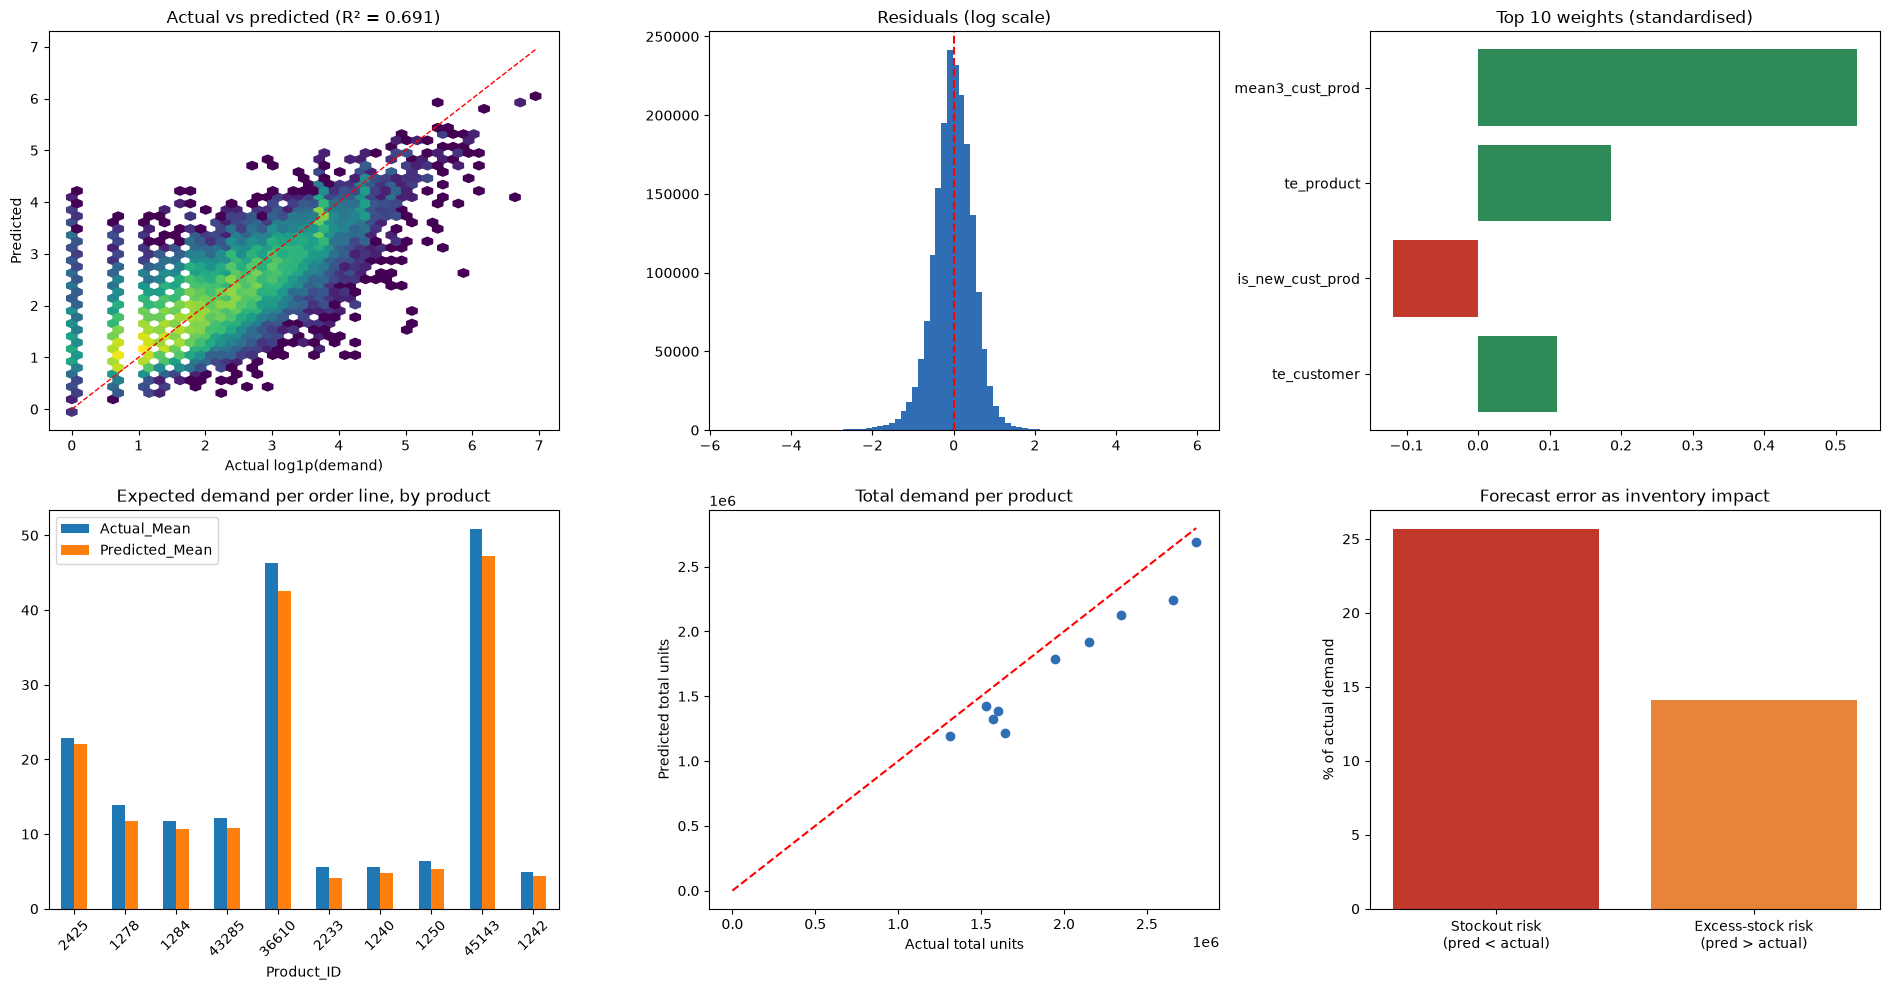

Under-forecast (stockout risk): 25.7% of demand | Over-forecast (excess stock): 14.1% of demand


In [23]:
fig, ax = plt.subplots(2, 3, figsize=(19, 10))
s = val.sample(min(60000, len(val)), random_state=0)
ax[0, 0].hexbin(s.y_log, s.pred_log, gridsize=45, cmap="viridis", bins="log", mincnt=1)
lim = [0, max(s.y_log.max(), s.pred_log.max())]; ax[0, 0].plot(lim, lim, "r--", lw=1)
ax[0, 0].set_xlabel("Actual log1p(demand)"); ax[0, 0].set_ylabel("Predicted"); ax[0, 0].set_title(f"Actual vs predicted (R² = {m1['R2_log']:.3f})")
ax[0, 1].hist(val.y_log - val.pred_log, bins=80, color="#2f6db5"); ax[0, 1].axvline(0, color="r", ls="--"); ax[0, 1].set_title("Residuals (log scale)")
top = coefs_df.head(10).iloc[::-1]
ax[0, 2].barh(top.feature, top["weight (standardised)"], color=["#2e8b57" if v > 0 else "#c0392b" for v in top["weight (standardised)"]]); ax[0, 2].set_title("Top 10 weights (standardised)")
pr = prod_res.set_index("Product_ID")[["Actual_Mean", "Predicted_Mean"]]; pr.index = pr.index.astype(str)
pr.plot.bar(ax=ax[1, 0], rot=45); ax[1, 0].set_title("Expected demand per order line, by product")
ax[1, 1].scatter(prod_res.Actual_Total, prod_res.Predicted_Total, color="#2f6db5"); mx = max(prod_res.Actual_Total.max(), prod_res.Predicted_Total.max())
ax[1, 1].plot([0, mx], [0, mx], "r--"); ax[1, 1].set_xlabel("Actual total units"); ax[1, 1].set_ylabel("Predicted total units"); ax[1, 1].set_title("Total demand per product")
inv = inventory_report(y9, pred9)
ax[1, 2].bar(["Stockout risk\n(pred < actual)", "Excess-stock risk\n(pred > actual)"], [inv["under_forecast_pct_of_demand"], inv["over_forecast_pct_of_demand"]], color=["#c0392b", "#e8833a"])
ax[1, 2].set_ylabel("% of actual demand"); ax[1, 2].set_title("Forecast error as inventory impact")
plt.tight_layout(); plt.show()
print(f"Under-forecast (stockout risk): {inv['under_forecast_pct_of_demand']:.1f}% of demand | Over-forecast (excess stock): {inv['over_forecast_pct_of_demand']:.1f}% of demand")

## 9. Freeze the equation: save the model and reload it to prove it works

In [24]:
builder.update(wk9)                              # history through week 9 -> used for test weeks 10 and 11
builder.slim()                                   # drop raw sums, store float32 -> smaller file
model.save(config.FINAL_MODEL_PATH, SEL)
with open(config.FINAL_BUILDER_PATH, "wb") as f: pickle.dump(builder, f, protocol=pickle.HIGHEST_PROTOCOL)
prod_res.to_csv(config.FINAL_PRODUCT_PATH, index=False); coefs_df.to_csv(config.FINAL_COEF_PATH, index=False)
trainlog.to_csv(config.FINAL_TRAINLOG_PATH, index=False); acc.product_week().to_csv(config.FINAL_WEEKLY_PATH, index=False)
ladder.to_csv(config.FINAL_DIR / "feature_ladder.csv", index=False); cand_tbl.to_csv(config.FINAL_DIR / "candidate_features.csv")
np.savez(config.FINAL_REF_PATH, X=X_first.to_numpy(), pred=pred9[:len(X_first)])
bins = np.linspace(0, 8, 81)
pd.DataFrame({"bin_left": bins[:-1], "actual": np.histogram(y9, bins, density=True)[0], "predicted": np.histogram(pred9, bins, density=True)[0]}).to_csv(config.FINAL_DIR / "val_distribution.csv", index=False)
json.dump({"target_skew": sk["skewness"].to_dict(), "quantiles": {str(k): v for k, v in q.items()}, "corr_sales_vs_demand": corr_sales,
           "quality": acc.quality().to_dict(), "rows_total": int(acc.n)}, open(config.FINAL_EDA_PATH, "w"), indent=2)
json.dump({"scope": {"train_table": TABLE, "test_table": config.FILTERED_TEST_TABLE, "products": PRODUCTS, "n_products": len(PRODUCTS),
                     "train_rows_by_week": {int(w): int(n) for w, n in week_rows.items()}, "train_rows_total": int(week_rows.sum()),
                     "sampling": "none - all rows used"},
           "weeks": {"seed": SEED_WEEK, "train": TRAIN_WEEKS, "val": VAL_WEEK},
           "hyperparameters": {"learning_rate": LEARNING_RATE, "epochs_per_chunk": EPOCHS_PER_CHUNK, "mini_batch_size": MINI_BATCH_SIZE,
                               "l2": L2, "max_rows_per_chunk": SUB_BATCH_ROWS},
           "validation_1_week_ahead": m1, "validation_2_weeks_ahead": m2, "closed_form": mcf, "baseline": base, "inventory": inv,
           "intercept_original": w0, "intercept_standardised": float(model.b), "formula": formula, "features": SEL, "candidates": CAND, "removed_features": removed,
           "selection": {"corr_drop": CORR_DROP, "min_gain": MIN_GAIN, "min_drop": MIN_DROP, "target_cap_q": TARGET_CAP_Q, "target_cap_units": float(cap_units)},
           "train_gd": tr_gd, "ladder": ladder.to_dict("records"),
           "val_feature_means": dict(zip(SEL, fmean.tolist())), "val_feature_stds": dict(zip(SEL, fstd.tolist()))},
          open(config.FINAL_METRICS_PATH, "w"), indent=2)
print("Saved to", config.FINAL_DIR)

# ---- reload check (proof that the saved artifacts work)
m_re, feats_re = LinearRegressionGD.load(config.FINAL_MODEL_PATH)
ref = np.load(config.FINAL_REF_PATH)
ok_pred = np.allclose(m_re.predict(ref["X"]), ref["pred"]); w0_re, _ = m_re.raw_coefficients()
with open(config.FINAL_BUILDER_PATH, "rb") as f: b_re = pickle.load(f)
ok_feat = b_re.transform(wk9.head(500))[SEL].shape == (500, len(SEL))
print(f"Reload check -> predictions identical: {ok_pred} | intercept identical: {np.isclose(w0_re, w0)} | feature builder works: {ok_feat}")
print("PASS" if (ok_pred and ok_feat and np.isclose(w0_re, w0)) else "FAIL")

Saved to C:\Users\Nhi\bimbo-gd-project\outputs\final
Reload check -> predictions identical: True | intercept identical: True | feature builder works: True
PASS


## 10. Summary
- The target is right-skewed; `log1p` (plus a cap on the extreme training values) removes most of the skew.
- From the candidate features, duplicates were removed, then the **feature ladder** showed the R² and MSE as each feature enters. Features that add less than `MIN_GAIN` were dropped.
- The **final equation** (section 8) was learned with Gradient Descent on all rows of weeks 4–8, and checked on week 9: training and validation R² are compared in section 7.
- A linear model cannot capture non-linear interactions, and customers/products without history only get averages (cold start).

➡️ Continue with `05_test_full_filtered.ipynb`: it applies this frozen equation to the test table (weeks 10 and 11).